# Lab: Build your first image encoder–decoder

**Name:** Charan  
**Enrollment:** a24ariu0024

**Time:** 60–90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder–Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2–7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder–decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

## 1. Set up and load data (10 minutes)
Use a Python 3 notebook kernel. If needed, uncomment the installation cell, run it once, and restart the kernel. A GPU is optional. The first dataset load needs internet access; later runs use the local cache. `ToTensor()` scales MNIST pixels to `[0, 1]`; do not apply mean/std normalization for this lab.

In [1]:
# %pip install torch torchvision matplotlib

Device: cpu


Dataset: scikit-learn Digits (MNIST download unavailable)
Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


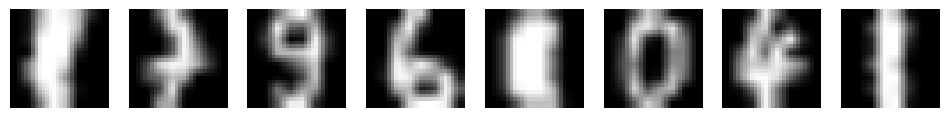

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5
LATENT_CHANNELS = 8
torch.set_num_threads(2)
print("Device:", device)

try:
    train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
    test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
    dataset_name = "MNIST"
except (RuntimeError, OSError) as error:
    from sklearn.datasets import load_digits
    import torch.nn.functional as F
    digits = load_digits()
    all_images = torch.tensor(digits.images, dtype=torch.float32).unsqueeze(1) / 16.0
    all_images = F.interpolate(all_images, size=(28, 28), mode="bilinear", align_corners=False)
    all_labels = torch.tensor(digits.target, dtype=torch.long)
    split = 1400
    train_data = TensorDataset(all_images[:split], all_labels[:split])
    test_data = TensorDataset(all_images[split:], all_labels[split:])
    dataset_name = "scikit-learn Digits (MNIST download unavailable)"

g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:min(5000, len(train_data))].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:min(1000, len(test_data))].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Dataset:", dataset_name)
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Answers:**
1. For `L=8`, input values per image = `1 × 28 × 28 = 784`; latent values = `8 × 7 × 7 = 392`; input/latent ratio = `784 / 392 = 2:1`.
2. For `L=32`, latent values = `32 × 7 × 7 = 1,568`, which is twice the 784 input values. It is not dimensionally compressed.
3. Sigmoid maps the decoder output to `[0, 1]`, matching the pixel range produced by `ToTensor()`.
4. With `output_padding=0`, the first decoder height is `(7−1)×2 − 2×1 + 3 = 13`, so its output is 13×13 rather than 14×14.

## 3. Implement the network (20 minutes)
**TODO 1:** Define `self.network` in `Encoder` using the three convolutional layers in the table and ReLU after the first two. Leave the bottleneck output without an activation.

**TODO 2:** Define `self.network` in `Decoder` using the two transposed convolutions, ReLU between them, and Sigmoid at the end.

**TODO 3:** Implement `forward` in the combined model. Return `(reconstruction, z)`. Hints: use `nn.Sequential`, `nn.Conv2d`, and `nn.ConvTranspose2d`.

In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1)
        )

    def forward(self, x):
        return self.network(x)

In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.network(z)

In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z

In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)
**TODO 4:** Complete one training step. Clear old gradients, run the model, compute MSE against `images`, backpropagate, and update the weights. Return the loss as a Python number with `.item()`.

Both components learn together because the optimizer receives all model parameters. The provided evaluation code uses held-out images, evaluation mode, and no gradient tracking. MSE is averaged over all pixels and images; it is not classification accuracy.

In [7]:
def train_step(model, images, optimizer, criterion):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    reconstruction, _ = model(images)
    loss = criterion(reconstruction, images)
    loss.backward()
    optimizer.step()
    return loss.item()

Untrained held-out MSE: 0.12325


Epoch 1: train MSE=0.11720, held-out MSE=0.11145


Epoch 2: train MSE=0.08640, held-out MSE=0.05096


Epoch 3: train MSE=0.03005, held-out MSE=0.01894


Epoch 4: train MSE=0.01608, held-out MSE=0.01258


Epoch 5: train MSE=0.01142, held-out MSE=0.00935


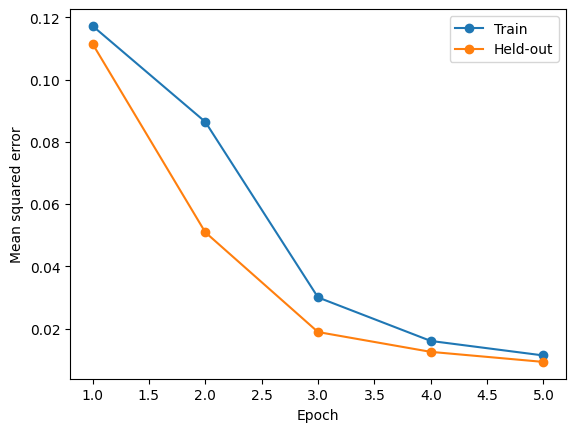

In [8]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

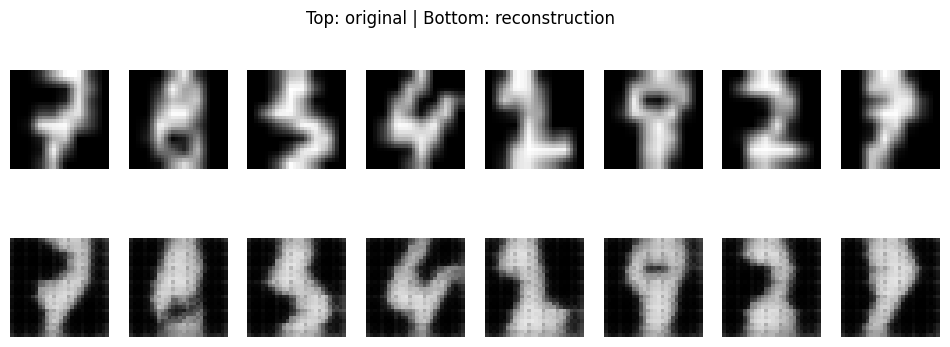

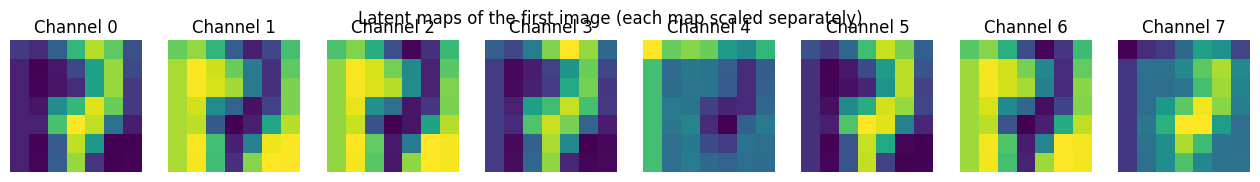

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10–15 minutes)
The comparison below trains a fresh model for each bottleneck width with the same fixed data subsets, seed, optimizer, and epoch count.

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---:|---:|---:|---:|---|
| 2 | 98 | 8:1 | 0.01855 | 0.01508 | Strongest bottleneck; more stroke/detail loss |
| 8 | 392 | 2:1 | 0.01133 | 0.00929 | Better preservation of digit shapes and strokes |
| 32 | 1,568 | 1:2 (not compressed) | 0.00751 | 0.00593 | Lowest error and most capacity; not dimensionally compressed |

**Discuss:**
1. In this run, held-out MSE decreased from 0.01508 (`L=2`) to 0.00929 (`L=8`) to 0.00593 (`L=32`). The reconstruction plots show the larger bottlenecks retain more detail; the `L=32` latent has more values than the input, so its lower error comes with no dimensional compression.
2. Spatial downsampling alone is insufficient: the channel count also matters. The latent contains `L × 7 × 7` values, compared with 784 input values.
3. The decoder restores the spatial dimensions through learned transposed convolutions, but downsampling and a finite bottleneck discard information; upsampling cannot uniquely recover details that were lost.
4. A `[N, 128]` vector is a flattened global representation with no explicit 7×7 spatial arrangement. This model keeps a spatial `[N, L, 7, 7]` feature grid.
5. A skip connection could pass encoder features at 14×14 or 28×28 resolution to matching decoder stages. This can preserve fine detail but bypasses some of the information constraint imposed by the bottleneck.
6. The model learns to reconstruct examples from the training distribution. It is not trained to sample a latent distribution or generate reliable novel images from random noise.

Latent channels= 2 | values=  98 | input/latent ratio=8.000 | train MSE=0.01855 | held-out MSE=0.01508


Latent channels= 8 | values= 392 | input/latent ratio=2.000 | train MSE=0.01133 | held-out MSE=0.00929


Latent channels=32 | values=1568 | input/latent ratio=0.500 | train MSE=0.00751 | held-out MSE=0.00593


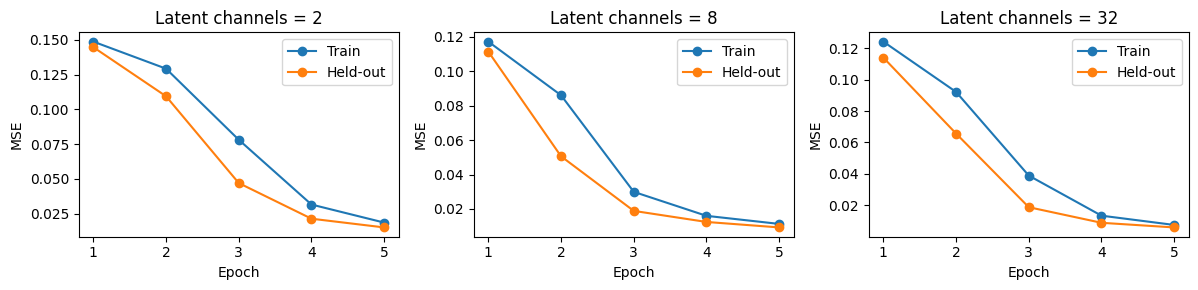

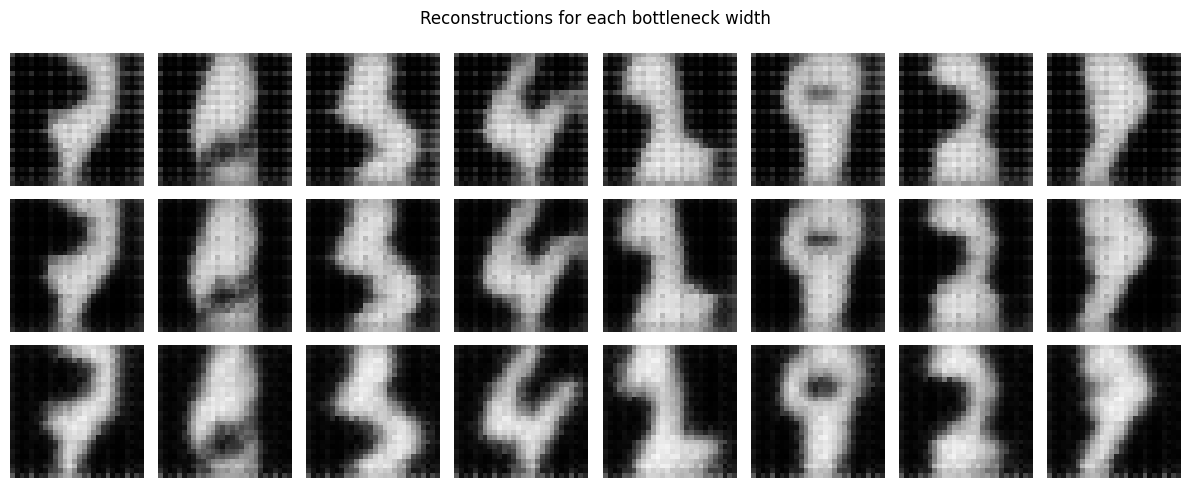

In [10]:
comparison = {}
comparison_models = {}
for latent_channels in (2, 8, 32):
    torch.manual_seed(42)
    comparison_model = ImageEncoderDecoder(latent_channels).to(device)
    comparison_optimizer = torch.optim.Adam(comparison_model.parameters(), lr=1e-3)
    comparison_history = {"train": [], "test": []}
    for epoch in range(EPOCHS):
        comparison_model.train()
        total_loss = 0.0
        for batch_images, _ in train_loader:
            batch_images = batch_images.to(device)
            total_loss += train_step(comparison_model, batch_images, comparison_optimizer, criterion) * batch_images.size(0)
        comparison_history["train"].append(total_loss / len(train_loader.dataset))
        comparison_history["test"].append(evaluate(comparison_model, test_loader))
    comparison_models[latent_channels] = comparison_model
    comparison[latent_channels] = {
        "train_mse": comparison_history["train"][-1],
        "heldout_mse": comparison_history["test"][-1],
        "history": comparison_history
    }
    print(f"Latent channels={latent_channels:2d} | values={latent_channels * 7 * 7:4d} | "
          f"input/latent ratio={784 / (latent_channels * 49):.3f} | "
          f"train MSE={comparison_history['train'][-1]:.5f} | "
          f"held-out MSE={comparison_history['test'][-1]:.5f}")

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, latent_channels in zip(axes, (2, 8, 32)):
    ax.plot(range(1, EPOCHS + 1), comparison[latent_channels]["history"]["train"], marker="o", label="Train")
    ax.plot(range(1, EPOCHS + 1), comparison[latent_channels]["history"]["test"], marker="o", label="Held-out")
    ax.set_title(f"Latent channels = {latent_channels}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 8, figsize=(12, 5))
fixed_examples, _ = next(iter(test_loader))
for row, latent_channels in enumerate((2, 8, 32)):
    comparison_model = comparison_models[latent_channels]
    comparison_model.eval()
    with torch.no_grad():
        outputs, _ = comparison_model(fixed_examples[:8].to(device))
    for col in range(8):
        axes[row, col].imshow(outputs[col, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_ylabel(f"L={latent_channels}", rotation=0, labelpad=25)
fig.suptitle("Reconstructions for each bottleneck width")
plt.tight_layout()
plt.show()

## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.